# Build the Zimbabwe extra-input tables

This notebook reproduces the integration steps used to build the model-ready monthly and static feature tables. It starts from the canonical observation/month keys, the six Earth Engine exports, aligned public datasets, and the downloaded SRTM and SoilGrids features. Outputs are written to a separate `notebook_rebuild` folder so the production files are not overwritten.

In [1]:
from pathlib import Path
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd().resolve()
if REPO.name == 'notebooks':
    REPO = REPO.parent
PROJECT = REPO.parent
ROOT = Path(os.environ.get(
    'CROPYIELD_EXTRA_INPUTS_ROOT',
    PROJECT / 'presto_extra_inputs_2026-11-09',
)).expanduser().resolve()
DERIVED = ROOT / 'derived'
INCOMING = ROOT / 'incoming'
OUTPUT = ROOT / 'notebook_rebuild'
OUTPUT.mkdir(parents=True, exist_ok=True)
KEYS = ['obs_id', 'season_year', 'month']
print('Repository:', REPO.name)
print('Input root:', ROOT.name)
print('Notebook output:', OUTPUT.name)

Repository: DSC-291-Final-Project
Input root: presto_extra_inputs_2026-11-09
Notebook output: notebook_rebuild


## 1. Load the canonical observation and month structure

The table contains one row per observation and growing-season month. The expected structure is 2,266 observations, nine months per observation, and 20,394 unique rows.

In [2]:
fields = pd.read_csv(DERIVED / 'zimbabwe_fields_2022_2023.csv')
month_keys = pd.read_csv(DERIVED / 'zimbabwe_field_months_2022_2023.csv', dtype={'obs_id':'string', 'month':'string'})
assert len(fields) == 2266
assert len(month_keys) == 20394
assert not month_keys.duplicated(KEYS).any()
assert month_keys.groupby('obs_id').size().eq(9).all()
display(month_keys.groupby('season_year').agg(observations=('obs_id','nunique'), monthly_rows=('obs_id','size')))

,observations,monthly_rows
season_year,,
2022,169,1521
2023,2097,18873


## 2. Align CHIRPS monthly precipitation

The earlier CHIRPS file stored months as `YYYY-MM-01`, while the canonical keys use `YYYY-MM`. We standardize the month representation and perform a one-to-one join.

In [3]:
chirps_source = PROJECT / 'external_data_2026-11-06' / 'derived' / 'chirps_observation_month.csv'
chirps = pd.read_csv(chirps_source, dtype={'obs_id':'string', 'month':'string'}).rename(columns={'year':'season_year', 'precip':'chirps_precip_mm'})
chirps['month'] = chirps['month'].str.slice(0, 7)
assert not chirps.duplicated(KEYS).any()
chirps_keep = KEYS + ['chirps_precip_mm', 'chirps_lat', 'chirps_lon']
chirps_aligned = month_keys[KEYS].merge(chirps[chirps_keep], on=KEYS, how='left', validate='one_to_one')
chirps_aligned['chirps_available'] = chirps_aligned['chirps_precip_mm'].notna()
assert chirps_aligned['chirps_available'].all()
print('CHIRPS complete rows:', int(chirps_aligned['chirps_available'].sum()))
print('Unique CHIRPS cells:', chirps_aligned[['chirps_lat','chirps_lon']].drop_duplicates().shape[0])

CHIRPS complete rows: 20394
Unique CHIRPS cells: 416


## 3. Load and clean the six Earth Engine exports

The six files contain Sentinel-1, ERA5-Land, Earth Engine SRTM and AlphaEarth. Earth Engine used `-9999` as an explicit export sentinel for missing pixels; it is converted back to `NaN`, never to zero.

In [4]:
gee_files = sorted(INCOMING.glob('zimbabwe_presto_s1_era5_srtm_2022_2023_part*.csv'))
assert len(gee_files) == 6, f'Expected six exports, found {len(gee_files)}'
gee = pd.concat([pd.read_csv(path, dtype={'obs_id':'string', 'month':'string'}) for path in gee_files], ignore_index=True)
assert len(gee) == 20394
assert not gee.duplicated(KEYS).any()
excluded = set(KEYS + ['latitude', 'longitude', '.geo'])
value_columns = [column for column in gee.columns if column not in excluded]
for column in value_columns:
    gee[column] = pd.to_numeric(gee[column], errors='coerce').replace(-9999, np.nan)
gee = gee.copy()
print('Rows:', len(gee), 'Columns:', len(gee.columns))
print('AlphaEarth dimensions:', len([c for c in gee if c.startswith('A') and c[1:].isdigit()]))

Rows: 20394 Columns: 95
AlphaEarth dimensions: 64


## 4. Select one Sentinel-1 orbit direction per observation

Ascending and descending radar observations have different viewing geometries. We count valid months for each direction and choose the direction with more coverage for each observation. Descending is the deterministic tie-breaker. The selected direction remains fixed across the entire season.

In [5]:
for direction in ('asc', 'desc'):
    gee[f'valid_{direction}'] = (
        gee[f's1_{direction}_count'].fillna(0).gt(0)
        & gee[f'VV_{direction}_median3'].notna()
        & gee[f'VH_{direction}_median3'].notna()
    )
orbit_coverage = gee.groupby('obs_id')[['valid_asc','valid_desc']].sum()
orbit_coverage['s1_orbit'] = np.where(orbit_coverage['valid_asc'] > orbit_coverage['valid_desc'], 'asc', 'desc')
gee = gee.merge(orbit_coverage[['s1_orbit']], on='obs_id', validate='many_to_one')
for statistic in ('point', 'median3'):
    for band in ('VV', 'VH'):
        gee[f's1_{band}_{statistic}_db'] = np.where(
            gee['s1_orbit'].eq('asc'),
            gee[f'{band}_asc_{statistic}'],
            gee[f'{band}_desc_{statistic}'],
        )
gee['s1_scene_count'] = np.where(gee['s1_orbit'].eq('asc'), gee['s1_asc_count'], gee['s1_desc_count'])
gee['s1_available'] = (gee['s1_scene_count'].fillna(0).gt(0) & gee['s1_VV_median3_db'].notna() & gee['s1_VH_median3_db'].notna())
display(orbit_coverage['s1_orbit'].value_counts().rename('observations'))
print('Valid Sentinel-1 monthly rows:', int(gee['s1_available'].sum()))
print('Observations with all nine months:', int(gee.groupby('obs_id')['s1_available'].sum().eq(9).sum()))

s1_orbit
desc    2128
asc      138
Name: observations, dtype: int64

Valid Sentinel-1 monthly rows: 704
Observations with all nine months: 31


## 5. Apply the official Presto normalization

The normalized columns use Presto's published constants. Raw values are retained for auditing. Missing Sentinel-1 values remain `NaN` and should stay masked in the model.

In [6]:
gee['presto_VV'] = (gee['s1_VV_median3_db'] + 25.0) / 25.0
gee['presto_VH'] = (gee['s1_VH_median3_db'] + 25.0) / 25.0
gee['presto_temperature_2m'] = (gee['temperature_2m'] - 272.15) / 35.0
gee['presto_total_precipitation'] = gee['total_precipitation'] / 0.03
gee['presto_elevation'] = gee['elevation'] / 2000.0
gee['presto_slope'] = gee['slope'] / 50.0
gee['era5_available'] = gee[['temperature_2m','total_precipitation']].notna().all(axis=1)
gee['srtm_gee_available'] = gee[['elevation','slope']].notna().all(axis=1)
assert gee['era5_available'].all() and gee['srtm_gee_available'].all()
display(pd.DataFrame({
    'channel':['VV','VH','temperature_2m','total_precipitation','elevation','slope'],
    'normalization':['(x+25)/25','(x+25)/25','(x-272.15)/35','x/0.03','x/2000','x/50']
}))

,channel,normalization
0,VV,(x+25)/25
1,VH,(x+25)/25
2,temperature_2m,(x-272.15)/35
3,total_precipitation,x/0.03
4,elevation,x/2000
5,slope,x/50


## 6. Assemble the monthly table

CHIRPS and Earth Engine features are joined by observation, season and month. Static SRTM values are joined by observation and repeated across nine months. AlphaEarth is retained in this table for traceability but should be modelled through the static table because it is annual.

In [7]:
srtm = pd.read_csv(DERIVED / 'srtm_features.csv', dtype={'obs_id':'string'})
alpha_columns = sorted(c for c in gee.columns if c.startswith('A') and c[1:].isdigit())
gee_keep = KEYS + [
    's1_orbit','s1_scene_count','s1_available',
    's1_VV_point_db','s1_VH_point_db','s1_VV_median3_db','s1_VH_median3_db',
    'temperature_2m','total_precipitation','era5_available',
    'elevation','slope','srtm_gee_available',
    'presto_VV','presto_VH','presto_temperature_2m',
    'presto_total_precipitation','presto_elevation','presto_slope',
] + alpha_columns
monthly = month_keys.merge(
    chirps_aligned[KEYS + ['chirps_precip_mm','chirps_available']], on=KEYS, validate='one_to_one'
).merge(
    srtm.drop(columns=['srtm_tile']), on='obs_id', validate='many_to_one'
).merge(
    gee[gee_keep], on=KEYS, validate='one_to_one'
)
assert len(monthly) == 20394 and not monthly.duplicated(KEYS).any()
assert monthly.groupby('obs_id').size().eq(9).all()
display(monthly.head(3))

,obs_id,season_year,month,latitude,longitude,chirps_precip_mm,chirps_available,srtm_elevation_m_point,srtm_elevation_m_3x3_median,srtm_slope_deg_point,...,A54,A55,A56,A57,A58,A59,A60,A61,A62,A63
0,zimbabwe:0002e51c-5124-4614-bb1b-1c1ae307de80,2023,2022-10,-19.076742,28.67022,14.00613,True,1212.0,1212.0,0.0,...,-0.032541,-0.093564,0.055363,-0.113741,-0.130165,-0.041584,0.153787,0.038447,0.084214,-0.221453
1,zimbabwe:0002e51c-5124-4614-bb1b-1c1ae307de80,2023,2022-11,-19.076742,28.67022,130.26682,True,1212.0,1212.0,0.0,...,-0.032541,-0.093564,0.055363,-0.113741,-0.130165,-0.041584,0.153787,0.038447,0.084214,-0.221453
2,zimbabwe:0002e51c-5124-4614-bb1b-1c1ae307de80,2023,2022-12,-19.076742,28.67022,86.56731,True,1212.0,1212.0,0.0,...,-0.032541,-0.093564,0.055363,-0.113741,-0.130165,-0.041584,0.153787,0.038447,0.084214,-0.221453


## 7. Assemble the static table

The static table has one row per observation. It combines field identifiers, downloaded SRTM, SoilGrids and one annual AlphaEarth vector.

In [8]:
soil = pd.read_csv(DERIVED / 'soilgrids_features.csv', dtype={'obs_id':'string'})
alpha = gee[['obs_id','season_year'] + alpha_columns].drop_duplicates('obs_id').copy()
alpha['alphaearth_complete'] = alpha[alpha_columns].notna().all(axis=1)
static = fields.merge(srtm, on='obs_id', validate='one_to_one').merge(soil, on='obs_id', validate='one_to_one').merge(alpha, on=['obs_id','season_year'], validate='one_to_one')
assert len(static) == 2266 and static['obs_id'].is_unique
assert static[alpha_columns].notna().all().all()
print('Static rows:', len(static))
print('Complete SoilGrids observations:', int(static['soilgrids_complete'].sum()))
print('Complete AlphaEarth observations:', int(static['alphaearth_complete'].sum()))

Static rows: 2266
Complete SoilGrids observations: 2265
Complete AlphaEarth observations: 2266


## 8. Save, validate and compare with the production files

In [9]:
monthly_path = OUTPUT / 'model_ready_monthly_extra_inputs.csv'
static_path = OUTPUT / 'model_ready_static_extra_inputs.csv'
monthly.to_csv(monthly_path, index=False)
static.to_csv(static_path, index=False)
production_monthly = pd.read_csv(DERIVED / 'model_ready_monthly_extra_inputs.csv')
production_static = pd.read_csv(DERIVED / 'model_ready_static_extra_inputs.csv')
assert len(production_monthly) == len(monthly)
assert len(production_static) == len(static)
assert set(production_monthly.columns) == set(monthly.columns)
assert set(production_static.columns) == set(static.columns)
summary = {
    'monthly_rows': len(monthly),
    'static_rows': len(static),
    'unique_monthly_keys': len(monthly.drop_duplicates(KEYS)),
    'era5_complete_rows': int(monthly['era5_available'].sum()),
    'srtm_complete_rows': int(monthly['srtm_gee_available'].sum()),
    'sentinel1_complete_rows': int(monthly['s1_available'].sum()),
    'alphaearth_dimensions': len(alpha_columns),
}
(OUTPUT / 'rebuild_summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
display(pd.Series(summary, name='value'))
print('Saved:', monthly_path.relative_to(ROOT))
print('Saved:', static_path.relative_to(ROOT))

monthly_rows               20394
static_rows                 2266
unique_monthly_keys        20394
era5_complete_rows         20394
srtm_complete_rows         20394
sentinel1_complete_rows      704
alphaearth_dimensions         64
Name: value, dtype: int64

Saved: notebook_rebuild/model_ready_monthly_extra_inputs.csv
Saved: notebook_rebuild/model_ready_static_extra_inputs.csv


## 9. Visualize monthly source completeness

,month,expected,sentinel1,era5,srtm
0,2021-10,169,100.0,100.0,100.0
1,2021-11,169,100.0,100.0,100.0
2,2021-12,169,100.0,100.0,100.0
3,2022-01,169,18.343195,100.0,100.0
4,2022-02,169,18.343195,100.0,100.0
5,2022-03,169,18.343195,100.0,100.0
6,2022-04,169,18.343195,100.0,100.0
7,2022-05,169,18.343195,100.0,100.0
8,2022-06,169,18.343195,100.0,100.0
9,2022-10,2097,0.0,100.0,100.0


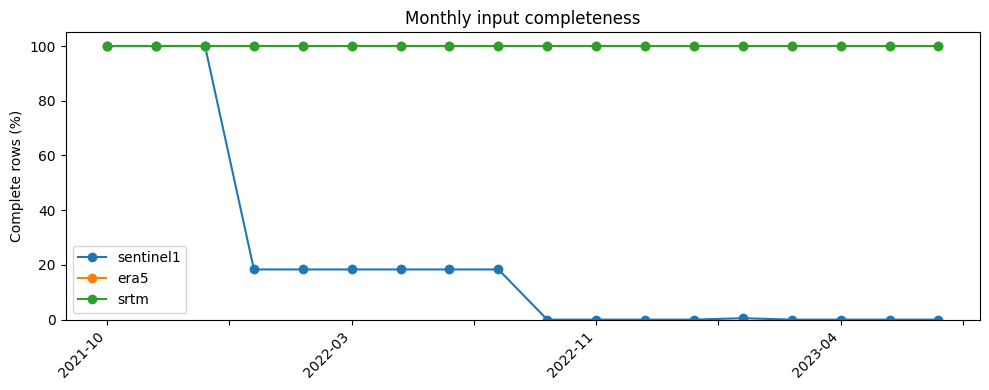

In [10]:
coverage = monthly.groupby('month', as_index=False).agg(expected=('obs_id','size'), sentinel1=('s1_available','sum'), era5=('era5_available','sum'), srtm=('srtm_gee_available','sum'))
for column in ['sentinel1','era5','srtm']:
    coverage[column] = 100 * coverage[column] / coverage['expected']
display(coverage)
ax = coverage.plot(x='month', y=['sentinel1','era5','srtm'], marker='o', figsize=(10,4))
ax.set(xlabel='', ylabel='Complete rows (%)', ylim=(0,105), title='Monthly input completeness')
plt.xticks(rotation=45, ha='right')
plt.tight_layout(); plt.show()